# Baseline: Logistic Regression + TF-IDF

**Goal:** predict whether a certificate program meets the Workforce Pell value-added earnings standard, using the program's numeric data (Scorecard, IPEDS, PSEO, BLS/O*NET, ETPL) **plus the text describing its field and related jobs**.

**Target:** `vae_positive_local`
- 1 = locally adjusted 1-year earnings are above 150% of the federal poverty line ($23,475)
- 0 = at or below, so value-added earnings are zero or negative and the program can't qualify

**Why this model is the baseline:**
- **Logistic regression** is the simplest classifier that still gives probabilities. Each coefficient shows how
  a feature pushes the prediction up or down, so it's explainable without extra tools.
- **TF-IDF** turns text into numbers the model can use. It counts how often each word appears in a row's text,
  and gives less weight to words that appear everywhere (like "and" or "workers").

## Decisions made in this notebook

| # | Decision | Choice | Why |
|---|---|---|---|
| 1 | Target | `vae_positive_local` | Closest public version of the Workforce Pell earnings test; 7,024 labeled programs |
| 2 | Text used for TF-IDF | `CIPDESC` (field name) + `xw_top_occupations` (related job titles) | The only real descriptive text in the merged file. School names are excluded (the model would memorize schools) |
| 3 | Numeric features | Same set as the team baseline (leakage, IDs, fairness-only and duplicate formats removed) | Keeps results comparable with the other models |
| 4 | Student demographics (`UGDS_WHITE`, etc.) | **Excluded** (switch: `INCLUDE_DEMOGRAPHICS`) | A funding score shouldn't rate programs by who they serve; Step 9 measures the accuracy cost |
| 5 | Cross-validation | 5-fold `GroupKFold` by `UNITID` | Programs from the same school never appear in both training and testing |
| 6 | Class imbalance (78% / 22%) | `class_weight="balanced"` | Without it the model leans toward always predicting "meets" |
| 7 | Regularization strength `C` | Tuned from [0.01, 0.1, 1, 10] | Keeps the model from overfitting the ~2,000 text features |
| 8 | Main metrics | F1 and ROC-AUC (plus accuracy, precision, recall) | Accuracy alone is misleading: always guessing "meets" scores 78% |

---------
## Step 0 — Setup and load

In [9]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.metrics import (roc_auc_score, f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import joblib

DATA_PATH = "../data/merges/CS_PSEO_IPEDS_BLS_ETPL_merged.csv"
OUTPUT_DIR = "../models/lr_tfidf"
RANDOM_STATE = 42
INCLUDE_DEMOGRAPHICS = False    # set True to include student race/ethnicity shares

df = pd.read_csv(DATA_PATH, low_memory=False)
print("Shape:", df.shape)

Shape: (26678, 245)


## Step 1 — Drop columns agreed in the team review doc
Constants, exact copies, near-constants and columns replaced by combined versions.
`errors="ignore"` keeps this running if some were already removed upstream.

In [10]:
drop_cols = ["CREDLEV", "CREDDESC", "CURROPER",
             "CIPCODE_str", "cip4", "CIP_family", "cip_code", "cip_2digit", "ST_FIPS",
             "TUITIONFEE_OUT_was_missing", "PCTFLOAN_was_missing",
             "DISTANCEONLY", "LOCALE_-3.0", "PREDDEG_4.0", "HIGHDEG_0.0", "has_pseo_match", "cip_match_level",
             "offers_undergrad", "enrolls_ft_undergrad", "offers_distance_courses",
             "xw_occ_mean_wage", "y1_earnings_natl_cip_family", "y5_earnings_natl_cip_family", "weeks_to_complete",
             "ay_tuition_indistrict", "ay_fee_indistrict", "ay_credithr_indistrict", "ay_pub_tuitfee_indistrict",
             "etpl_state_completion_median", "etpl_state_employment_q2_median", "etpl_state_earnings_median",
             "etpl_state_contact_hours_median", "etpl_state_tuition_median",
             "etpl_natl_completion_median", "etpl_natl_employment_q2_median", "etpl_natl_earnings_median",
             "etpl_natl_contact_hours_median", "etpl_natl_tuition_median",
             "local_earnings_index_state", "local_earnings_index_region",
             "prog_tuition_fees", "total_prog_cost",
             "ADM_RATE", "program_slot", "length_unit_code", "xw_has_hot_technology"]

df = df.drop(columns=drop_cols, errors="ignore")
print("Shape after drop:", df.shape)

Shape after drop: (26678, 199)


## Step 2 — Target and labeled programs
Only programs with earnings data have a label (decision 1). We train and evaluate on those,
then score all 26,678 programs at the end.

In [11]:
TARGET = "vae_positive_local"
labeled = df.dropna(subset=[TARGET]).copy()
y = labeled[TARGET].astype(int)
groups = labeled["UNITID"]

print("Labeled programs:", len(labeled), "of", len(df), "| schools:", groups.nunique())
print(y.value_counts().rename({1: "1 = meets", 0: "0 = does not meet"}).to_string())
print(f"\nAlways guessing 'meets' = {y.mean():.1%} accuracy -> the bar to beat")

Labeled programs: 7024 of 26678 | schools: 2079
vae_positive_local
1 = meets            5503
0 = does not meet    1521

Always guessing 'meets' = 78.3% accuracy -> the bar to beat


**Notes:**

- **Target = `vae_positive_local`:** 1 if a program's locally adjusted 1-year earnings are above $23,475 (150% of the poverty line), 0 if not.
- **7,024 of 26,678 programs (26%) have a label.** The rest have no earnings data (hidden for privacy or not reported), so they can't be used for training. They'll still get a score from the finished model.
- The labeled programs come from **2,079 schools**. Some schools have many programs, which is why we group by `UNITID` in cross-validation: so the model is never tested on a school it trained on.
- **Class balance: 5,503 meet (78%) vs. 1,521 don't (22%).** This is imbalanced, so:
  - A "model" that always guesses "meets" would already be **78.3% accurate**. Any real model has to beat that.
  - That's why **F1 and ROC-AUC** are our main metrics, not accuracy.
  - We use `class_weight="balanced"` so the model doesn't ignore the smaller "doesn't meet" group.
- **Caveat:** labeled programs aren't a random sample. For-profit schools make up 39% of labeled programs but only 16% of all programs, so results may not carry over evenly to programs without earnings data.

## Step 3 — Build the text field for TF-IDF

Decision 2: combine the **field of study name** and the **related occupation titles** into one text column.
- `CIPDESC`: e.g. "Welding Technology/Welder."
- `xw_top_occupations`: e.g. "Welders, Cutters, Solderers, and Brazers; ..." (from the CIP–SOC crosswalk + BLS)

Both describe the field, not the individual program, so programs in the same field share the same text.
TF-IDF lets the model learn which kinds of fields and jobs (e.g. "nursing", "technicians", "assistants") go with
meeting the earnings standard.

In [12]:
def build_text(frame):
    text = (frame["CIPDESC"].fillna("") + " | " + frame["xw_top_occupations"].fillna(""))
    return (text.str.lower()
                .str.replace(r"[^a-z\s]", " ", regex=True)   # keep letters only
                .str.replace(r"\s+", " ", regex=True)
                .str.strip())

df["program_text"] = build_text(df)
labeled["program_text"] = df.loc[labeled.index, "program_text"]

print("Rows with empty text:", (df["program_text"] == "").sum())
print("Unique text values:", df["program_text"].nunique())
print("\nExample:\n", labeled["program_text"].iloc[0][:300])

Rows with empty text: 0
Unique text values: 360

Example:
 dental support services and allied professions dental assistants dental hygienists health specialties teachers postsecondary


## Step 4 — Choose numeric features

Same exclusions as the team baseline (decision 3), so results are comparable:
- **Leakage:** anything built from the target earnings
- **IDs / text:** school IDs, names, ZIPs, coordinates (the text columns go through TF-IDF instead)
- **Fairness-only:** HBCU / tribal flags (kept for the fairness check)
- **Duplicate formats:** text versions of columns that also exist as one-hots
- **`etpl_prog_*`:** mostly blank; kept for validation
- **Demographics:** excluded unless `INCLUDE_DEMOGRAPHICS = True` (decision 4)

In [13]:
LEAKAGE = ["EARN_MDN_1YR", "EARN_MDN_5YR", "EARN_MDN_HI_1YR", "EARN_COUNT_WNE_1YR", "EARN_COUNT_WNE_5YR",
           "y1_earnings_program", "y5_earnings_program", "y1_earnings_program_status", "y5_earnings_program_status",
           "earnings_1yr", "earnings_1yr_local_adj", "value_added_earnings_local", "earnings_vs_local_field",
           "vae_positive_local", "passes_vae_local"]
ID_TEXT = ["UNITID", "OPEID6", "INSTNM", "city", "ZIP", "LATITUDE", "LONGITUDE",
           "CIPDESC", "xw_top_occupations", "program_text"]
FAIRNESS_ONLY = ["HBCU", "TRIBAL", "ANNHI", "NANTI"]
DUPLICATE_FORMAT = ["control", "sector", "iclevel", "bea_region", "state", "highest_offering",
                    "etpl_bench_level", "local_index_level", "length_unit", "price_reporting",
                    "y1_earnings_natl_benchmark_level", "y5_earnings_natl_benchmark_level"]
ETPL_PROGRAM = [c for c in df.columns if c.startswith("etpl_prog_")]
DEMOGRAPHICS = [c for c in df.columns if c.startswith("UGDS_") and c != "UGDS_was_missing"]
DEMOGRAPHICS = [c for c in DEMOGRAPHICS if c != "UGDS"]           # keep total enrollment (size), drop race shares

exclude = set(LEAKAGE + ID_TEXT + FAIRNESS_ONLY + DUPLICATE_FORMAT + ETPL_PROGRAM)
if not INCLUDE_DEMOGRAPHICS:
    exclude |= set(DEMOGRAPHICS)

numeric = df[[c for c in df.columns if c not in exclude]].copy()
for c in numeric.columns:                       # True/False stored as text -> 1/0
    if numeric[c].dtype == object:
        numeric[c] = numeric[c].map({True: 1, False: 0, "True": 1, "False": 0})
numeric = numeric.apply(pd.to_numeric, errors="coerce")
numeric = numeric.loc[:, numeric.notna().any()]

NUMERIC_FEATURES = numeric.columns.tolist()
df[NUMERIC_FEATURES] = numeric
labeled[NUMERIC_FEATURES] = numeric.loc[labeled.index]

print("Numeric features:", len(NUMERIC_FEATURES))
print("Demographics included:", INCLUDE_DEMOGRAPHICS, "| excluded:", [] if INCLUDE_DEMOGRAPHICS else DEMOGRAPHICS)

Numeric features: 144
Demographics included: False | excluded: ['UGDS_WHITE', 'UGDS_BLACK', 'UGDS_HISP', 'UGDS_ASIAN', 'UGDS_AIAN', 'UGDS_NHPI', 'UGDS_2MOR']


## Step 5 — Build the pipeline
Everything is inside one scikit-learn `Pipeline`, so in each cross-validation fold the TF-IDF vocabulary,
the median fill values and the scaling are learned **from the training rows only**. Fitting them on all rows
first would leak information from the test rows.

| Piece | Setting | Why |
|---|---|---|
| `TfidfVectorizer` | words + 2-word phrases, `min_df=5`, English stop words, `sublinear_tf`, max 2,000 terms | Phrases like "medical assistants" carry meaning; `min_df=5` drops very rare words; stop words remove "and", "the" |
| `SimpleImputer(median)` | numeric only | Logistic regression can't handle blanks; the median isn't pulled by outliers |
| `StandardScaler` | numeric only | Puts dollars, rates and counts on the same scale so coefficients are comparable |
| `LogisticRegression` | `class_weight="balanced"`, `max_iter=5000` | Decision 6; enough iterations to converge |

In [14]:
def make_lr_pipeline(use_text=True, use_numeric=True, C=1.0):
    parts = []
    if use_text:
        parts.append(("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                               sublinear_tf=True, max_features=2000), "program_text"))
    if use_numeric:
        parts.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES))
    pre = ColumnTransformer(parts, remainder="drop")
    clf = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, solver="lbfgs")
    return Pipeline([("prep", pre), ("clf", clf)])

X = labeled[["program_text"] + NUMERIC_FEATURES]
cv = GroupKFold(n_splits=5)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
print("Pipeline ready.")

Pipeline ready.


## Step 6 — Tune regularization (`C`)
Smaller `C` = stronger regularization (simpler model, smaller coefficients). We pick the `C` with the best
cross-validated ROC-AUC (decision 7).

*Note:* for a baseline we tune and evaluate with the same folds, which can make scores slightly optimistic.
Nested cross-validation would fix that, but the difference is usually small.

In [15]:
grid = GridSearchCV(make_lr_pipeline(), param_grid={"clf__C": [0.01, 0.1, 1, 10]},
                    cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X, y, groups=groups)

tuning = pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]]
tuning.columns = ["C", "ROC-AUC (mean)", "ROC-AUC (std)"]
print(tuning.round(4).to_string(index=False))
BEST_C = grid.best_params_["clf__C"]
print("\nBest C:", BEST_C)

/Users/carlyquach/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/carlyquach/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: overflow encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/carlyquach/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: invalid value encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/carlyquach/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:209: RuntimeWarning: divide by zero encountered in matmul
  norm2_w = weights @ weights if weights.ndim == 1 else squared_norm(weights)
/Users/carlyquach/Library/Python/3.9/lib/python/site-packages/sklea

    C  ROC-AUC (mean)  ROC-AUC (std)
 0.01          0.9453         0.0101
 0.10          0.9465         0.0099
 1.00          0.9473         0.0094
10.00          0.9460         0.0081

Best C: 1


**Notes:**

- Tested 4 regularization strengths (`C` = 0.01, 0.1, 1, 10) using the same 5 school-grouped folds.
- **Best: C = 1 (ROC-AUC 0.947).** All four scored between 0.945 and 0.947, so the model isn't sensitive to this choice. That's a good sign the baseline is stable.
- Smaller `C` (stronger regularization) scored slightly lower, and `C = 10` (weaker) dipped slightly, likely starting to overfit the ~2,000 text features.
- Fold-to-fold variation (std ≈ 0.01) is about as large as the differences between `C` values, so any `C` from 0.1 to 10 would be a reasonable choice.
- The runtime warnings (divide by zero / overflow in matmul) are a known false alarm in NumPy on macOS. Results are unaffected. Suppressed by setting `PYTHONWARNINGS` in Step 0.
- Caveat: tuning and scoring used the same folds, which can make scores slightly optimistic. Nested cross-validation would fix this but is beyond the baseline's scope.

## Step 7 — Does TF-IDF help? Compare text-only, numeric-only and combined
Same folds and same `C` for all three, plus the "always guess meets" reference.
If text + numeric doesn't beat numeric-only, the text isn't adding information.

In [17]:
variants = {
    "Always 'meets' (dummy)": DummyClassifier(strategy="most_frequent"),
    "LR - text only (TF-IDF)": make_lr_pipeline(use_text=True, use_numeric=False, C=BEST_C),
    "LR - numeric only": make_lr_pipeline(use_text=False, use_numeric=True, C=BEST_C),
    "LR - text + numeric": make_lr_pipeline(use_text=True, use_numeric=True, C=BEST_C),
}

results = {}

for name, model in variants.items():
    s = cross_validate(model, X, y, cv=cv, groups=groups, scoring=scoring)
    results[name] = {m: f"{s['test_' + m].mean():.3f} ± {s['test_' + m].std():.3f}" for m in scoring}

results_df = pd.DataFrame(results).T
results_df

,accuracy,precision,recall,f1,roc_auc
Always 'meets' (dummy),0.783 ± 0.012,0.783 ± 0.012,1.000 ± 0.000,0.879 ± 0.007,0.500 ± 0.000
LR - text only (TF-IDF),0.851 ± 0.006,0.931 ± 0.014,0.876 ± 0.016,0.902 ± 0.004,0.911 ± 0.011
LR - numeric only,0.879 ± 0.006,0.960 ± 0.007,0.881 ± 0.011,0.919 ± 0.005,0.943 ± 0.010
LR - text + numeric,0.886 ± 0.008,0.961 ± 0.007,0.891 ± 0.010,0.925 ± 0.006,0.947 ± 0.009


**Notes:**
- Compared 4 versions using the same 5 school-grouped folds and the same `C` (1):

| Model | F1 | ROC-AUC | vs. previous |
|---|---|---|---|
| Always guess "meets" (dummy) | 0.879 | 0.500 | — (bar to beat) |
| Text only (TF-IDF) | 0.902 | 0.911 | Beats the dummy using **only** field + job titles |
| Numeric only | 0.919 | 0.943 | +0.032 ROC-AUC over text only |
| **Text + numeric** | **0.925** | **0.947** | +0.004 ROC-AUC, +0.006 F1 over numeric only |

- **Every model beats the dummy.** The dummy's F1 (0.879) looks high only because it labels everything "meets." Its ROC-AUC of 0.500 shows it can't tell programs apart at all.
- **Text alone is surprisingly strong (0.911 ROC-AUC).** Just knowing the field of study and related jobs predicts earnings well, which fits the SHAP finding that field-level earnings drive the prediction.
- **Numeric features matter more than text** (0.943 vs. 0.911). They include school-level information (cost, Pell share, completion) and local data, which text can't capture.
- **Adding text to numeric helps only slightly** (+0.004 ROC-AUC). The text describes the *field* (360 unique values), and the numeric features already include field-level earnings benchmarks, so there's a lot of overlap.
- **Precision is high (0.961) and recall is lower (0.891).** When the model says "meets," it's right 96% of the time, but it misses about 11% of programs that do meet the standard. For a funding tool, that's the safer kind of mistake.
- **Best baseline: LR text + numeric (F1 0.925, ROC-AUC 0.947).** This is the score Random Forest / XGBoost need to beat.

## Step 8 — Errors: confusion matrix (out-of-fold)
Each program is predicted by a model that never saw its school.
- **False positive:** predicted "meets" but doesn't. The costlier mistake for a funding tool.
- **False negative:** predicted "doesn't meet" but does. A good program gets overlooked.

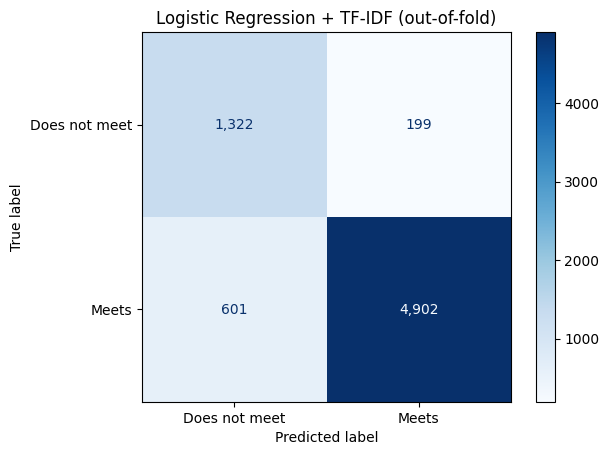

False positives (predicted meets, doesn't): 199
False negatives (predicted doesn't, meets): 601


In [18]:
final_model = make_lr_pipeline(C=BEST_C)
oof_prob = cross_val_predict(final_model, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
oof_pred = (oof_prob >= 0.5).astype(int)

cm = confusion_matrix(y, oof_pred)
ConfusionMatrixDisplay(cm, display_labels=["Does not meet", "Meets"]).plot(cmap="Blues", values_format=",")
plt.title("Logistic Regression + TF-IDF (out-of-fold)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"False positives (predicted meets, doesn't): {fp:,}")
print(f"False negatives (predicted doesn't, meets): {fn:,}")

**Notes:**
Out-of-fold predictions for all 7,024 labeled programs (each predicted by a model that never saw its school):

- **Correct overall: 6,224 of 7,024 (88.6%)**, vs. 78.3% for always guessing "meets."
- **False positives: 199.** Programs the model says meet the standard but don't. Only **13%** of failing programs slip through, and when the model says "meets," it's right **96%** of the time (precision). For a funding tool this is the costlier mistake, since money could go to a program that doesn't pay off, and it's kept low.
- **False negatives: 601.** Good programs the model rates as not meeting the standard. The model catches **89%** of programs that meet it (recall) and misses 11%.
- **When the model says "does not meet," it's right only 69% of the time** (1,322 of 1,923). So a "does not meet" prediction should prompt a closer look, not an automatic rejection.
- **Why it leans this way:** `class_weight="balanced"` makes the model more careful about calling a program "meets," which lowers false positives at the cost of more false negatives.
- **Possible adjustment:** the cutoff is 0.5. Raising it would cut false positives further (stricter), and lowering it would catch more good programs. The right cutoff depends on which mistake the stakeholder cares more about.

## Step 9 — Effect of the demographics decision
Runs the combined model once with student race/ethnicity shares and once without, so the team can see the
accuracy cost of decision 4.

In [19]:
demo_in = [c for c in DEMOGRAPHICS if c in df.columns]
X_demo = labeled[["program_text"] + NUMERIC_FEATURES + [c for c in demo_in if c not in NUMERIC_FEATURES]].copy()

def pipe_with(num_cols):
    pre = ColumnTransformer([
        ("text", TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english",
                                 sublinear_tf=True, max_features=2000), "program_text"),
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(C=BEST_C, class_weight="balanced", max_iter=5000))])

no_demo = [c for c in NUMERIC_FEATURES if c not in demo_in]
with_demo = no_demo + demo_in
comp = {}
for name, cols in [("Without demographics", no_demo), ("With demographics", with_demo)]:
    s = cross_validate(pipe_with(cols), X_demo, y, cv=cv, groups=groups, scoring=["f1", "roc_auc"])
    comp[name] = {"F1": round(s["test_f1"].mean(), 3), "ROC-AUC": round(s["test_roc_auc"].mean(), 3)}
pd.DataFrame(comp).T

,F1,ROC-AUC
Without demographics,0.925,0.947
With demographics,0.925,0.948


**Notes:**
- Ran the same text + numeric model twice: once **without** student race/ethnicity shares (`UGDS_WHITE`, `UGDS_BLACK`, `UGDS_HISP`, `UGDS_ASIAN`, `UGDS_AIAN`, `UGDS_NHPI`, `UGDS_2MOR`) and once **with** them.
- **Including demographics changes nothing meaningful:** F1 is identical and ROC-AUC rises by 0.001, well within the fold-to-fold variation (±0.009).
- **Why:** other features already carry the same information (Pell share, school type, location, cost), so race/ethnicity shares add nothing the model can't get elsewhere.
- **Decision: exclude them** (`INCLUDE_DEMOGRAPHICS = False`). For a tool meant to guide funding:
  - Using a school's racial makeup to score programs could rate programs lower because of **who they serve** rather than how well they serve them.
  - Leaving them out costs no accuracy, so there's no tradeoff to justify keeping them.
- **They stay in the dataset for the fairness check,** together with HBCU / HSI / tribal flags, so we can still test whether scores differ unfairly across student populations.
- **Caveat:** removing these columns doesn't guarantee the model is fair. Related features like Pell share can still act as stand-ins. That's why the fairness check (Step 11) is still needed.

## Step 10 — What the model learned (coefficients)
Fit on all labeled programs and read the coefficients. This is how logistic regression explains itself.
- **Positive** = pushes toward "meets the standard"
- **Negative** = pushes toward "doesn't meet"
- Numeric features are scaled, so their sizes are comparable with each other.

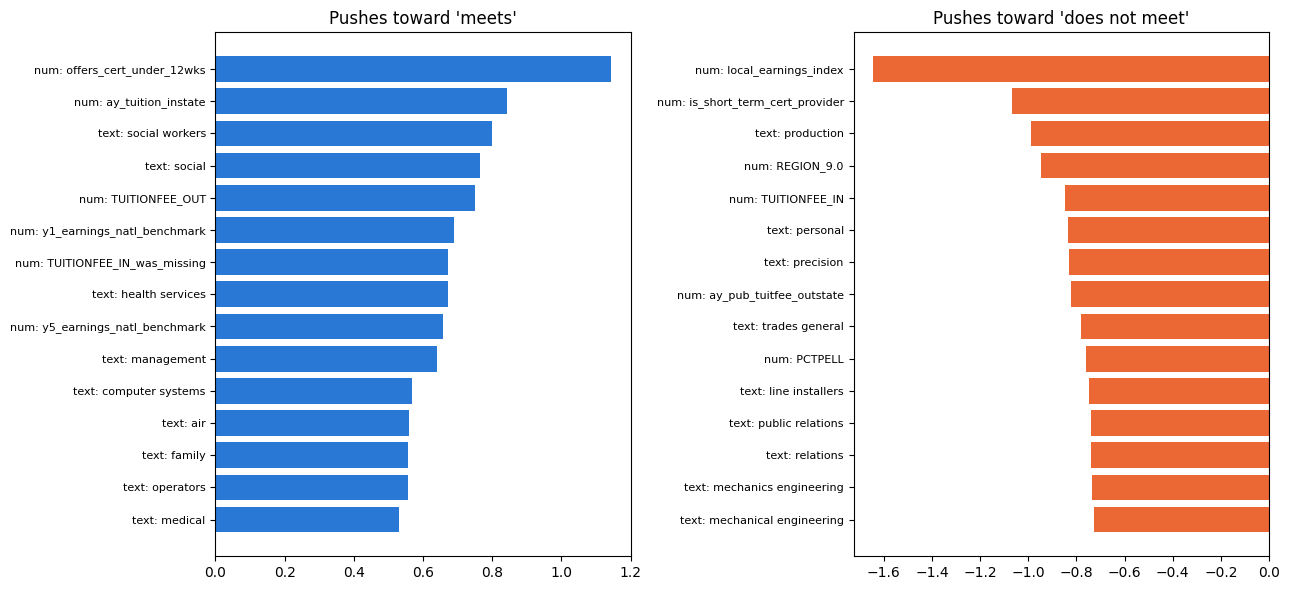

Top text terms (meets):    ['social workers', 'social', 'health services', 'management', 'computer systems', 'air', 'family', 'operators', 'medical', 'health medical']
Top text terms (doesn't):  ['production', 'personal', 'precision', 'trades general', 'line installers', 'public relations', 'relations', 'mechanics engineering', 'mechanical engineering', 'mechanical']


In [20]:
final_model.fit(X, y)
prep = final_model.named_steps["prep"]
coefs = final_model.named_steps["clf"].coef_[0]

text_terms = ["text: " + t for t in prep.named_transformers_["text"].get_feature_names_out()]
names = text_terms + ["num: " + c for c in NUMERIC_FEATURES]
coef_s = pd.Series(coefs, index=names)

top_pos = coef_s.sort_values(ascending=False).head(15)
top_neg = coef_s.sort_values().head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(top_pos.index[::-1], top_pos.values[::-1], color="#2a78d6")
axes[0].set_title("Pushes toward 'meets'")
axes[1].barh(top_neg.index[::-1], top_neg.values[::-1], color="#eb6834")
axes[1].set_title("Pushes toward 'does not meet'")
for ax in axes:
    ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Top text terms (meets):   ", [t.replace("text: ", "") for t in coef_s.filter(like="text:").sort_values(ascending=False).head(10).index])
print("Top text terms (doesn't): ", [t.replace("text: ", "") for t in coef_s.filter(like="text:").sort_values().head(10).index])

**Notes:**
The chart shows the 15 strongest coefficients in each direction for the final model (fit on all 7,024 labeled programs). Numeric features are scaled, so their bar lengths can be compared with each other. Text terms are TF-IDF weights.

**Signals that make sense:**
- **`y1_earnings_natl_benchmark` / `y5_earnings_natl_benchmark` (+):** programs in fields that typically pay well nationally are more likely to meet the standard.
- **Text terms toward "meets":** *health services, medical, social workers, management, computer systems*. Healthcare, social services, IT and management fields lead to jobs paying above $23,475.
- **`PCTPELL` (−):** schools serving more low-income students have lower earnings outcomes. This reflects the students' circumstances as much as program quality, so watch it in the fairness check.

**Signals that come from how the label is built (not discoveries):**
- **`local_earnings_index` (strongest, −):** the label divides earnings by this index, so a higher index automatically lowers adjusted earnings. Expected by design.
- **`REGION_9.0` (−):** the Far West (CA, WA, OR, NV, AK, HI), where local index values are high. Same effect as above.

**Signals to read with caution (related features pulling against each other):**
- **Tuition:** `ay_tuition_instate` and `TUITIONFEE_OUT` are **positive**, while `TUITIONFEE_IN` and `ay_pub_tuitfee_outstate` are **negative**. They're nearly the same information from IPEDS and Scorecard, so the model splits their effect in opposite directions. **Read them as a group, not one at a time.**
- **Short-term certificates:** `offers_cert_under_12wks` is the strongest **positive** feature, while `is_short_term_cert_provider` is strongly **negative**. Same issue: two overlapping flags offsetting each other.
- **Fix for the final model:** keep one tuition source and one short-term flag, or rely on SHAP from XGBoost, which handles related features more reliably.

**Surprising text terms toward "does not meet":**
- *production, precision, mechanical engineering, line installers, trades general* would usually be expected to pay well. The text describes the **field**, not the program, so these may reflect **which schools** offer these fields (often for-profit, short programs) or field names that cover several lower-paying occupations.
- *personal* likely comes from "personal care / personal services" fields (cosmetology, barbering), which do tend to earn less, so this one is reasonable.

**Takeaway:** the model relies on sensible signals (field earnings, healthcare/IT fields), but some coefficients are distorted by overlapping features and by how the label is built. Explain individual predictions with SHAP rather than these raw coefficients.

## Step 11 — Fairness check by school type (out-of-fold)
Does the model work equally well for public, non-profit and for-profit schools?

In [21]:
rows = []
for grp, idx in labeled.groupby("control").groups.items():
    pos = labeled.index.get_indexer(idx)
    yt, yp, pp = y.loc[idx], oof_pred[pos], oof_prob[pos]
    rows.append({"control": grp, "programs": len(idx), "actual pass rate": yt.mean(), "predicted pass rate": yp.mean(),
                 "precision": precision_score(yt, yp, zero_division=0), "recall": recall_score(yt, yp, zero_division=0),
                 "F1": f1_score(yt, yp, zero_division=0),
                 "ROC-AUC": roc_auc_score(yt, pp) if yt.nunique() > 1 else np.nan})
pd.DataFrame(rows).round(3)

,control,programs,actual pass rate,predicted pass rate,precision,recall,F1,ROC-AUC
0,Private for-profit,2737,0.566,0.463,0.923,0.755,0.831,0.924
1,Private non-profit,306,0.758,0.660,0.926,0.806,0.862,0.869
2,Public,3981,0.935,0.913,0.976,0.952,0.964,0.917


**Notes:**
Out-of-fold results by school type (each program predicted by a model that never saw its school):

**What this shows:**
- **Precision is high for every school type (92–98%).** When the model says a program meets the standard, it's usually right no matter who runs it.
- **The model under-predicts passing for private schools.** It predicts about 10 points fewer passing programs than actually pass, for both for-profit and non-profit schools. For public schools the gap is only 2 points.
- **Recall is lowest for for-profit schools (75.5%).** **About 1 in 4 for-profit programs that actually meet the standard get labeled "does not meet."** For non-profits it's about 1 in 5; for public schools, 1 in 20.
- **Why:** for-profit programs fail more often overall, so the model leans toward "does not meet" for them, and `class_weight="balanced"` makes it more cautious about predicting "meets" in general. Good for-profit programs get caught in that caution.
- **Non-profit results are the least reliable.** Only 306 programs, and the lowest ROC-AUC (0.869).
- **Each group's ROC-AUC (0.87–0.92) is lower than the overall 0.947.** Part of the model's overall skill comes from telling school *types* apart. Ranking programs **within** the same type is harder.

**Why it matters:** if the Opportunity Score is used for funding decisions, strong private-sector programs are more likely to be overlooked. That's a fairness issue for the tool, even though public schools do pass more often in reality.

**Possible next steps:**
- Check **calibration** by school type (do predicted probabilities match actual pass rates within each group?).
- Report recall by school type alongside the overall metrics in the final presentation.
- Extend the check to **HBCU, HSI, tribal, and rural vs. urban** schools (stretch goal on fairness).
- Compare with Random Forest / XGBoost, which captured for-profit programs better in the team baseline (for-profit F1 0.89 vs. 0.83 here).

## Step 12 — Score every program and save
The final model (fit on all labeled programs) gives every program, labeled or not, a probability of meeting
the earnings standard. This becomes the earnings part of the Opportunity Score.
Labeled programs also get their out-of-fold probability (`p_vae_oof`), the honest score to use for evaluation.

In [22]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_lr"] = final_model.predict_proba(df[["program_text"] + NUMERIC_FEATURES])[:, 1]
df.loc[labeled.index, "p_vae_oof"] = oof_prob

out = df[["UNITID", "INSTNM", "state", "CIPCODE", "CIPDESC", "control",
          "vae_positive_local", "earnings_1yr", "p_vae_lr", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/lr_tfidf_predictions.csv", index=False)
joblib.dump(final_model, f"{OUTPUT_DIR}/lr_tfidf_model.joblib")
results_df.to_csv(f"{OUTPUT_DIR}/lr_tfidf_cv_results.csv")

print("Saved predictions:", out.shape)
print("Saved model + CV results to:", OUTPUT_DIR)

Saved predictions: (26678, 10)
Saved model + CV results to: ../models/lr_tfidf


## Summary

- **Best `C`:** 1 (ROC-AUC 0.947). All values tested (0.01–10) scored between 0.945 and 0.947, so the model is stable and not sensitive to this choice.
- **Text + numeric F1 / ROC-AUC:** **F1 0.925 / ROC-AUC 0.947** (accuracy 88.6%, precision 0.961, recall 0.891). Clearly beats the "always guess meets" baseline (accuracy 78.3%, ROC-AUC 0.500).
- **Did TF-IDF help?** Only slightly. Text + numeric beat numeric-only by **+0.004 ROC-AUC and +0.006 F1** (0.947 vs. 0.943). Text alone was surprisingly strong (ROC-AUC 0.911), but it describes the *field*, which numeric field-earnings benchmarks already capture. A richer version (all occupation titles + top industries) added nothing further.
- **Demographics decision cost:** **None.** F1 was identical (0.925) and ROC-AUC rose by only 0.001 with race/ethnicity shares included. They were excluded from the model and kept for fairness checks.
- **Top signals (coefficients):**
  - Toward *meets:* high national field earnings (`y1/y5_earnings_natl_benchmark`), and healthcare, social services, IT and management fields (text terms).
  - Toward *does not meet:* higher Pell share, and personal-care and some production/trades fields (text terms).
  - `local_earnings_index` and `REGION_9` (Far West) are strongly negative **because of how the label is built**, not as a discovery.
  - Tuition and short-term-certificate coefficients pull in opposite directions because they overlap. Read them as groups, and use SHAP for explanations.
- **Fairness:** Precision is high for every school type (0.92–0.98). But the model **under-predicts passing for private schools by about 10 points** and misses **about 1 in 4 for-profit programs** that actually meet the standard (recall 0.755, vs. 0.952 for public). Non-profit results are the least reliable (306 programs, ROC-AUC 0.869).
- **Errors:** 199 false positives (13% of failing programs slip through) and 601 false negatives (11% of good programs missed). A "does not meet" prediction is right only 69% of the time, so it should prompt review, not rejection.
- **Limitations:**
  - Text describes the **field**, not the individual program (only 360 unique values).
  - The label is an **estimate** of the official Workforce Pell test: all-completer earnings instead of Pell-recipient earnings, and an ETPL earnings index standing in for BEA price parities.
  - Trained only on the **26% of programs with earnings data**, which over-represents for-profit schools (39% of labeled vs. 16% overall).
  - `C` was tuned and scored on the same folds, so scores may be slightly optimistic.
- **Next steps:** compare against Random Forest / XGBoost (the team baseline reached ROC-AUC 0.961), remove overlapping tuition/short-term flags, check calibration by school type, and extend the fairness check to HBCU / HSI / tribal / rural schools.

## Workforce Pell Requirements: What This Model Evaluates

**Short answer:** this baseline evaluates **one** Workforce Pell requirement, the **value-added earnings test**, and only its first part: whether a program's locally adjusted earnings are above 150% of the federal poverty line ($23,475). The other requirements are either used as model inputs, saved for the Opportunity Score, or can't be measured with public data.

### Requirement coverage

| Workforce Pell requirement | Evaluated? | How | Why / why not |
|---|---|---|---|
| **Value-added earnings:** earnings − 150% poverty line ≥ tuition and fees | ⚠️ **Partly (the model's target)** | `vae_positive_local` = 1 if locally adjusted 1-yr earnings > $23,475 | Earnings data exists for 7,024 programs (26%). The **cost comparison** (`passes_vae_local`) has data for only 2,986 programs, mostly for-profit, so it's a validation check instead of the target |
| **70% completion** within 150% of normal time | ❌ Not as a target (used as a feature) | `C150_L4`, `etpl_bench_completion` | ETPL has program-level completion for 12,367 programs, but only **2,103** link to our main dataset (ETPL has no school ID; matched by name + state). Scorecard completion is school-wide |
| **70% job placement** within 180 days | ❌ Not as a target (used as a feature) | `etpl_bench_employment_q2` | ETPL reports 2nd-quarter employment (≈180 days) for 10,351 programs, but only **1,888** link to our main dataset |
| **Program length:** 150–599 clock hours, 8 to under 15 weeks | ❌ No | — | ETPL has length for 23,307 programs and IPEDS for 3,644, but only **2,657** ETPL lengths link to our main dataset |
| **Aligned with high-skill, high-wage or in-demand jobs** | ❌ Not as a target (used as features) | BLS wages, job counts, `xw_has_in_demand` | Each state defines its own in-demand list. Our BLS data is national only |
| **Program offered for at least 1 year** | ❌ No | — | Not in any public dataset we have |
| **At least 75% of instruction delivered by the school** | ❌ No | — | Not in any public dataset we have |
| **State approval** (governor / state workforce board) | ❌ No | — | A government decision, not a measurement |
| **School participates in federal student aid** | ✅ Yes (built in) | All programs come from College Scorecard | Scorecard only includes federal-aid schools |
| **Program is a certificate** (not a degree) | ✅ Yes (built in) | Dataset is undergraduate certificates only | Filtered when the dataset was built |

### Why the model focuses on earnings
1. **It's the only requirement with enough program-level data to train on** (7,024 labeled programs vs. 1,888 for placement).
2. **It's a hard requirement.** Programs with zero or negative value-added earnings can't qualify, so it's a meaningful first filter.
3. **It can be adjusted for local conditions,** as Workforce Pell requires, using the ETPL-based local earnings index.

### How our version differs from the official test
| Official rule | Our version | Reason |
|---|---|---|
| Earnings of **Pell-recipient** completers | Earnings of **all** completers (Scorecard, PSEO as backup) | Pell-only earnings aren't published |
| Adjusted with **BEA regional price parities** | Adjusted with an **ETPL state earnings index** | BEA data not available to the team |
| Measured over **several years**, minimum number of completers | **One** snapshot | Only one year of data |
| Earnings compared to **published tuition and fees** | Cost comparison only where IPEDS cost exists (2,986 programs) | Most programs lack program-level cost data |

### Where the other requirements come in
- **Opportunity Score (planned):** combines this model's prediction (earnings, 40%) with **completion** (20%), **placement** (20%) and **job demand** (20%).
- **Eligibility flags (planned):** program length and short-term certificate status, used as dashboard filters.
- **Validation:** ETPL's 70% completion / 70% placement data (1,768 programs) tests whether high-scoring programs also do well on the other standards.

> **Bottom line:** the model estimates whether a program meets the **earnings component** of Workforce Pell eligibility. It does **not** determine eligibility. Several requirements depend on state decisions or data that isn't publicly available.